## 0. Setup and load data

In [1]:
# Colab dependencies
!pip -q install -U tensorflow transformers accelerate datasets

In [2]:
import os, re, html, json, random, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
warnings.filterwarnings("ignore")

from google.colab import files
uploaded = files.upload()
CSV_PATH = next((f for f in uploaded.keys() if f.lower().endswith(".csv")), None)
if CSV_PATH is None:
    raise FileNotFoundError("Upload the dataset CSV file.")
df_raw = pd.read_csv(CSV_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())
print("Columns:", df_raw.columns.tolist())

Saving urdu_sarcastic_dataset.csv to urdu_sarcastic_dataset (4).csv
Shape: (20060, 8)


,urdu_text,is_sarcastic,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہ...,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی...,1.0,NaN,NaN,NaN,NaN,NaN,NaN
2,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپ...,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,نہیں پائین 😎,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی...,1.0,NaN,NaN,NaN,NaN,NaN,NaN


Columns: ['urdu_text', 'is_sarcastic', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7']


## 1. Data audit and exploratory analysis

In [3]:
TEXT_COL, LABEL_COL = "urdu_text", "is_sarcastic"
missing_cols = [c for c in [TEXT_COL, LABEL_COL] if c not in df_raw.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

print("Missing values in required columns:")
display(df_raw[[TEXT_COL, LABEL_COL]].isna().sum().rename("missing_count").to_frame())
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))
print("Duplicate text rows:", int(df_raw[TEXT_COL].dropna().duplicated().sum()))

# Drop missing text/labels and invalid labels; coerce labels only if they are clean 0/1 values.
df = df_raw[[TEXT_COL, LABEL_COL]].copy()
df = df.dropna(subset=[TEXT_COL, LABEL_COL])
df[TEXT_COL] = df[TEXT_COL].astype(str)
df[LABEL_COL] = pd.to_numeric(df[LABEL_COL], errors="coerce")
df = df[df[LABEL_COL].isin([0, 1])].copy()
df[LABEL_COL] = df[LABEL_COL].astype(int)
print("Rows after dropping missing/invalid labels:", len(df))
print("Exact duplicate rows after cleaning:", int(df.duplicated().sum()))
print("Duplicate texts after cleaning:", int(df[TEXT_COL].duplicated().sum()))

# Remove exact duplicate text with conflicting labels is especially important for split hygiene, after reporting conflicts.
conflicts = df.groupby(TEXT_COL)[LABEL_COL].nunique()
conflict_texts = conflicts[conflicts > 1]
print("Texts with conflicting labels:", len(conflict_texts))
if len(conflict_texts):
    display(df[df[TEXT_COL].isin(conflict_texts.index)].sort_values(TEXT_COL).head(20))

# To prevent identical texts crossing splits, keep one copy per text.
ambiguous_texts = set(conflict_texts.index)
df = df[~df[TEXT_COL].isin(ambiguous_texts)].drop_duplicates(subset=[TEXT_COL], keep="first").reset_index(drop=True)
print("Modeling rows after text deduplication/conflict removal:", len(df))

Missing values in required columns:


,missing_count
urdu_text,105
is_sarcastic,56


Exact duplicate rows: 3646
Duplicate text rows: 4142
Rows after dropping missing/invalid labels: 19955
Exact duplicate rows after cleaning: 3545
Duplicate texts after cleaning: 4142
Texts with conflicting labels: 597


,urdu_text,is_sarcastic
305,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی...,1
5784,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی...,0
9283,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی...,1
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی...,1
5262,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی...,0
9127,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی...,1
529,`` پی ڈی ایم `` جلسے میں اس وقت عجیب ماحول بن...,1
1039,`` پی ڈی ایم `` جلسے میں اس وقت عجیب ماحول بن...,0
9677,`` پی ڈی ایم `` جلسے میں اس وقت عجیب ماحول بن...,1
14225,`` پی ڈی ایم `` جلسے میں اس وقت عجیب ماحول بن...,1


Modeling rows after text deduplication/conflict removal: 15216


,count,percent
is_sarcastic,,
0,9037,59.39
1,6179,40.61


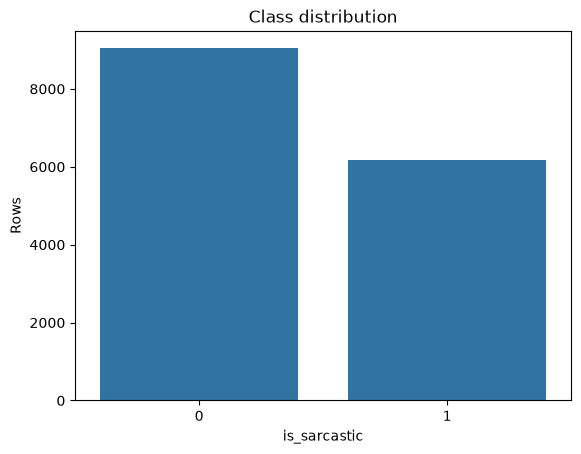

char_len                                                 \
                count    mean    std  min   25%    50%    75%    max   
is_sarcastic                                                           
0              9037.0   71.58  57.60  2.0  30.0   57.0   93.0  327.0   
1              6179.0  111.74  61.67  5.0  68.0  100.0  136.0  304.0   

             whitespace_token_len                                             
                            count   mean    std  min   25%   50%   75%   max  
is_sarcastic                                                                  
0                          9037.0  15.64  12.31  1.0   7.0  13.0  20.0  70.0  
1                          6179.0  23.68  12.87  1.0  15.0  21.0  29.0  71.0

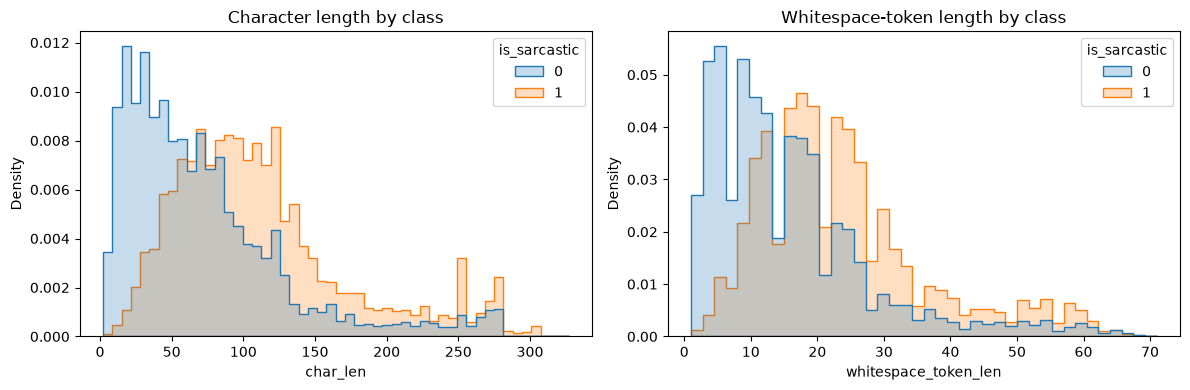

Representative examples (sampled per class):

Class 0:


,urdu_text
3535,کچھ شرم ہوتی کچھ حیا ہوتی ہے😶 اتنی بد عائیں ل...
2418,بزرگ نےایک جنازے میں شرکت کے بعد اسکی قبر کے ...
8531,ماشاءاللہ بهت بهت مبارک هو بهنا آقامرحبامدنیمر...
3924,طاہر بھائی کے پاس رسی پکڑی ہے کیا 😜🤣😂
9435,جیوندا رہو ویرے🙏💕😘
13532,کاش محشر میں جب ان کی آمد ہو اور بھیجیں سب اُن...
13852,پسند سے مراد یہ ہے بسکٹس میں نہیں کھاتی وہ کوئ...
12943,تمہارے بقول لڑای تو بڑوں کی تھی۔ 😂😂😂🤣🤣🤣



Class 1:


,urdu_text
7660,افغانان که جنت کې هم کېنوې، بیابه هم ددې لپاره...
2149,جھونکی۔پھرجب صحافت پرنٹنگ سےڈجٹل پر شفٹ ہوئی ت...
5048,@UmarCheema1 @HamidMirPAK @TalatHussain12 \nبو...
6253,جنکا آئ جی 125000 کا کمانڈر اتنا بہادر ہو تو ا...
7746,پائین سوچ رہا تھا لوگوں کو اپنا دیدار دیدوں 😅 ...
4899,ایک سیکیورٹی سٹیٹ کے وسائل، آمدن، قرضوں کی رقم...
4189,انڈے 216 روپے درجن ہوگئے ہیں مگر گندے انڈے اب...
15214,کاکا جب تم نے عِدت پوری نہیں ہونے دی 🤭 تو عوام...


In [4]:
counts = df[LABEL_COL].value_counts().sort_index()
distribution = pd.DataFrame({
    "count": counts,
    "percent": (counts / counts.sum() * 100).round(2)
})
display(distribution)
ax = sns.barplot(x=distribution.index.astype(str), y=distribution["count"])
ax.set(title="Class distribution", xlabel="is_sarcastic", ylabel="Rows")
plt.show()

# Raw character and whitespace-token lengths; token counts are only rough for Urdu/code-mixed text.
df["char_len"] = df[TEXT_COL].str.len()
df["whitespace_token_len"] = df[TEXT_COL].str.split().str.len()
display(df.groupby(LABEL_COL)[["char_len", "whitespace_token_len"]].describe().round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="char_len", hue=LABEL_COL, bins=50, element="step", stat="density", common_norm=False, ax=axes[0])
sns.histplot(data=df, x="whitespace_token_len", hue=LABEL_COL, bins=40, element="step", stat="density", common_norm=False, ax=axes[1])
axes[0].set_title("Character length by class")
axes[1].set_title("Whitespace-token length by class")
plt.tight_layout(); plt.show()

print("Representative examples (sampled per class):")
for label in [0, 1]:
    print(f"\nClass {label}:")
    display(df[df[LABEL_COL] == label][[TEXT_COL]].sample(min(8, (df[LABEL_COL] == label).sum()), random_state=SEED))

## 2. Urdu-aware preprocessing and stratified split

In [5]:
# Conservative normalization: Unicode NFKC, HTML unescape, normalize common Arabic/Persian
# variants used in Urdu. Preserve emoji, punctuation, hashtags, mentions, URLs, repetitions,
# Latin/Roman Urdu and code-mixed terms by default.
ARABIC_VARIANTS = str.maketrans({
    "ي": "ی", "ى": "ی", "ك": "ک", "ۀ": "ہ", "ة": "ہ",
    "ؤ": "و", "أ": "ا", "إ": "ا", "ٱ": "ا",
})

def normalize_urdu(text):
    text = html.unescape(str(text))
    text = unicodedata.normalize("NFKC", text)
    text = text.translate(ARABIC_VARIANTS)
    # Remove tatweel (kashida), which is usually typographic elongation.
    text = text.replace("ـ", "")
    # Collapse whitespace only; deliberately do not strip punctuation/emoji/repetition.
    text = re.sub(r"\s+", " ", text).strip()
    return text

def remove_emoji_approx(text):
    # Ablation only. Unicode ranges are approximate and will not catch every emoji sequence.
    emoji_re = re.compile(
        "["
        "\U0001F300-\U0001FAFF"
        "\U00002700-\U000027BF"
        "\U0001F1E6-\U0001F1FF"
        "]+", flags=re.UNICODE
    )
    return emoji_re.sub(" ", text)

df["text_norm"] = df[TEXT_COL].map(normalize_urdu)
df["text_no_emoji"] = df["text_norm"].map(remove_emoji_approx).str.replace(r"\s+", " ", regex=True).str.strip()
display(df[[TEXT_COL, "text_norm", "text_no_emoji"]].sample(min(10, len(df)), random_state=SEED))

from sklearn.model_selection import train_test_split
X = df["text_norm"].to_numpy()
y = df[LABEL_COL].to_numpy()
# First hold out test, then split the remaining data into train/validation.
X_trainval, X_test, y_trainval, y_test, idx_trainval, idx_test = train_test_split(
    X, y, np.arange(len(df)), test_size=0.15, stratify=y, random_state=SEED
)
X_train, X_val, y_train, y_val, idx_train, idx_val = train_test_split(
    X_trainval, y_trainval, idx_trainval, test_size=0.1764705882,
    stratify=y_trainval, random_state=SEED
) # approx 70/15/15 overall
print("Split sizes:", len(X_train), len(X_val), len(X_test))
for name, yy in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(name, pd.Series(yy).value_counts(normalize=True).sort_index().round(3).to_dict())

,urdu_text,text_norm,text_no_emoji
1087,😭😭😭😭 مرشد میں تے مولانا دی کراچی جلسے چ اکانوم...,😭😭😭😭 مرشد میں تے مولانا دی کراچی جلسے چ اکانوم...,مرشد میں تے مولانا دی کراچی جلسے چ اکانومی آلی...
11461,ہم دو چار دن مصروف کیا ہوئے، صحافیوں نے اپنے آ...,ہم دو چار دن مصروف کیا ہوئے، صحافیوں نے اپنے آ...,ہم دو چار دن مصروف کیا ہوئے، صحافیوں نے اپنے آ...
8725,میرے دل لکو بھا گئی ہیں یہ پتر,میرے دل لکو بھا گئی ہیں یہ پتر,میرے دل لکو بھا گئی ہیں یہ پتر
11232,اور ٹویٹر پر سندھ حکومت اور لفافہ اینکروں کو ...,اور ٹویٹر پر سندھ حکومت اور لفافہ اینکروں کو د...,اور ٹویٹر پر سندھ حکومت اور لفافہ اینکروں کو د...
10791,بے عزتی اور دبائو سندھ کے وزیر اعلی نے ڈالا اب...,بے عزتی اور دبائو سندھ کے وزیر اعلی نے ڈالا اب...,بے عزتی اور دبائو سندھ کے وزیر اعلی نے ڈالا اب...
884,ڈاکٹر عامر لیاقت کو فوجی بنا کر شہید قرار دے ر...,ڈاکٹر عامر لیاقت کو فوجی بنا کر شہید قرار دے ر...,ڈاکٹر عامر لیاقت کو فوجی بنا کر شہید قرار دے ر...
9386,بس ایک گھنٹہ دور ہوں ، پہنچ رہی 😂,بس ایک گھنٹہ دور ہوں ، پہنچ رہی 😂,بس ایک گھنٹہ دور ہوں ، پہنچ رہی
4556,تیرے جیسے چوتیوں اوہ میرا مطلب یوتھیوں کی بھی ...,تیرے جیسے چوتیوں اوہ میرا مطلب یوتھیوں کی بھی ...,تیرے جیسے چوتیوں اوہ میرا مطلب یوتھیوں کی بھی ...
12773,ایکسپورٹ تمہارے جیسے کھوتے ہی ہو سکتے ہیں، یا ...,ایکسپورٹ تمہارے جیسے کھوتے ہی ہو سکتے ہیں، یا ...,ایکسپورٹ تمہارے جیسے کھوتے ہی ہو سکتے ہیں، یا ...
5382,अल्लाह का फ़ज़ल ... अल्लाह के हबीब صلی اللہ ت...,अल्लाह का फ़ज़ल ... अल्लाह के हबीब صلی اللہ تع...,अल्लाह का फ़ज़ल ... अल्लाह के हबीब صلی اللہ تع...


Split sizes: 10650 2283 2283
train {0: 0.594, 1: 0.406}
validation {0: 0.594, 1: 0.406}
test {0: 0.594, 1: 0.406}


## 3. Metrics helpers

In [6]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report, confusion_matrix)

def metric_row(name, y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0,1], zero_division=0)
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_0": p[0], "recall_0": r[0], "f1_0": f[0],
        "precision_1": p[1], "recall_1": r[1], "f1_1": f[1],
        "macro_f1": f1_score(y_true, y_pred, average="macro")
    }

def evaluate(name, y_true, y_pred, plot=True):
    print(name)
    print(classification_report(y_true, y_pred, labels=[0,1],
                                target_names=["non-sarcastic (0)", "sarcastic (1)"],
                                digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=[0,1])
    if plot:
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"])
        plt.title(f"Confusion matrix — {name}"); plt.ylabel("Actual"); plt.xlabel("Predicted")
        plt.show()
    return metric_row(name, y_true, y_pred)

results = []

## 4. Classical baseline: word + character TF-IDF and Logistic Regression

In [7]:
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

word_char_features = FeatureUnion([
    ("word", TfidfVectorizer(analyzer="word", ngram_range=(1,2), min_df=2,
                             max_features=250000, sublinear_tf=True, strip_accents=None)),
    ("char", TfidfVectorizer(analyzer="char", ngram_range=(2,5), min_df=2,
                             max_features=300000, sublinear_tf=True))
])
tfidf_model = Pipeline([
    ("features", word_char_features),
    ("clf", LogisticRegression(max_iter=1500, class_weight="balanced",
                               C=2.0, random_state=SEED))
])
tfidf_model.fit(X_train, y_train)
val_pred_tfidf = tfidf_model.predict(X_val)
display(pd.DataFrame([metric_row("TF-IDF word+char / LogisticRegression", y_val, val_pred_tfidf)]))

,model,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
0,TF-IDF word+char / LogisticRegression,0.832676,0.858088,0.860619,0.859352,0.795233,0.791802,0.793514,0.826433


## 5. Ablation study: word vs character, and keeping vs removing emoji

In [8]:
def make_tfidf(kind="word_char", remove_emoji=False):
    if kind == "word":
        feats = TfidfVectorizer(analyzer="word", ngram_range=(1,2), min_df=2,
                                max_features=250000, sublinear_tf=True)
    elif kind == "char":
        feats = TfidfVectorizer(analyzer="char", ngram_range=(2,5), min_df=2,
                                max_features=300000, sublinear_tf=True)
    else:
        feats = FeatureUnion([
            ("word", TfidfVectorizer(analyzer="word", ngram_range=(1,2), min_df=2,
                                     max_features=250000, sublinear_tf=True)),
            ("char", TfidfVectorizer(analyzer="char", ngram_range=(2,5), min_df=2,
                                     max_features=300000, sublinear_tf=True))
        ])
    return Pipeline([("features", feats),
                     ("clf", LogisticRegression(max_iter=1500, class_weight="balanced",
                                                C=2.0, random_state=SEED))])

# Keep the same row split, only alter the text representation.
X_train_noemoji = df.loc[idx_train, "text_no_emoji"].to_numpy()
X_val_noemoji = df.loc[idx_val, "text_no_emoji"].to_numpy()
ablation_preds = {}
for kind in ["word", "char", "word_char"]:
    model = make_tfidf(kind)
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    ablation_preds[f"{kind}, emoji kept"] = pred
    results.append(metric_row(f"TF-IDF {kind}, emoji kept (validation)", y_val, pred))
    if kind == "word_char":
        model_noemoji = make_tfidf(kind)
        model_noemoji.fit(X_train_noemoji, y_train)
        pred_noemoji = model_noemoji.predict(X_val_noemoji)
        ablation_preds[f"{kind}, emoji removed"] = pred_noemoji
        results.append(metric_row(f"TF-IDF {kind}, emoji removed (validation)", y_val, pred_noemoji))

display(pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True))

,model,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
0,"TF-IDF word_char, emoji kept (validation)",0.832676,0.858088,0.860619,0.859352,0.795233,0.791802,0.793514,0.826433
1,"TF-IDF word_char, emoji removed (validation)",0.832238,0.857984,0.859882,0.858932,0.794372,0.791802,0.793085,0.826008
2,"TF-IDF char, emoji kept (validation)",0.825668,0.853767,0.852507,0.853137,0.784715,0.786408,0.785560,0.819348
3,"TF-IDF word, emoji kept (validation)",0.812527,0.850983,0.829646,0.840179,0.759625,0.787487,0.773305,0.806742


## 6. Neural classifier: Keras BiLSTM

Sequence length: 49
Epoch 1/12
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.7224 - loss: 0.5605 - val_accuracy: 0.8025 - val_loss: 0.4446 - learning_rate: 0.0010
Epoch 2/12
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8892 - loss: 0.2828 - val_accuracy: 0.7819 - val_loss: 0.5028 - learning_rate: 0.0010
Epoch 3/12
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9602 - loss: 0.1272 - val_accuracy: 0.7770 - val_loss: 0.6264 - learning_rate: 0.0010
Epoch 4/12
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9837 - loss: 0.0547 - val_accuracy: 0.7884 - val_loss: 0.7461 - learning_rate: 5.0000e-04


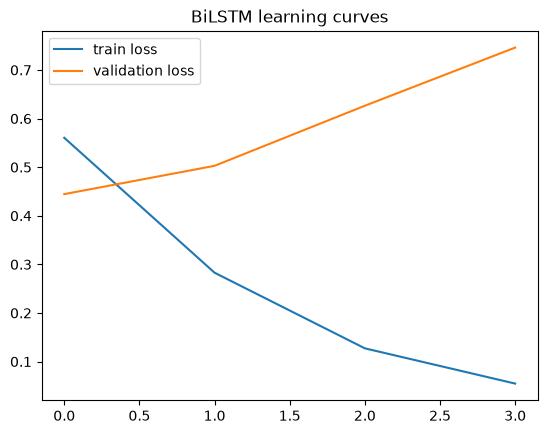

,model,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
0,BiLSTM (validation),0.802453,0.860558,0.79646,0.827269,0.731518,0.811219,0.769309,0.798289


In [10]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(SEED)
MAX_WORDS = 60000
MAX_LEN = int(np.clip(np.percentile([len(t.split()) for t in X_train], 95), 40, 180))
print("Sequence length:", MAX_LEN)

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>", filters="") # preserve punctuation/emojis
tokenizer.fit_on_texts(X_train)
def sequences(texts):
    return pad_sequences(tokenizer.texts_to_sequences(texts), maxlen=MAX_LEN, padding="post", truncating="post")
Xtr_seq, Xv_seq, Xte_seq = sequences(X_train), sequences(X_val), sequences(X_test)

inp = layers.Input(shape=(MAX_LEN,))
x = layers.Embedding(MAX_WORDS, 128, mask_zero=True)(inp)
x = layers.Bidirectional(layers.LSTM(64, dropout=0.25, recurrent_dropout=0.0))(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.35)(x)
out = layers.Dense(1, activation="sigmoid")(x)
bilstm = Model(inp, out)
bilstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
               loss="binary_crossentropy", metrics=["accuracy"])
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.5)
]
history = bilstm.fit(Xtr_seq, y_train, validation_data=(Xv_seq, y_val),
                     epochs=12, batch_size=128, callbacks=callbacks, verbose=1)
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.legend(); plt.title("BiLSTM learning curves"); plt.show()
val_prob_lstm = bilstm.predict(Xv_seq, verbose=0).ravel()
val_pred_lstm = (val_prob_lstm >= 0.5).astype(int)
display(pd.DataFrame([metric_row("BiLSTM (validation)", y_val, val_pred_lstm)]))

## 7. Transformer experiment: fine-tune XLM-RoBERTa

In [9]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import f1_score, accuracy_score
import gc
import torch

gc.collect()
torch.cuda.empty_cache()
print(torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "GiB"
)

CHECKPOINT = "xlm-roberta-base"
MAX_TOKENS = 96
BATCH_SIZE = 2
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

hf_tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)

hf_model = AutoModelForSequenceClassification.from_pretrained(
    CHECKPOINT,
    num_labels=2
)

# Reduce memory used for storing activations during backpropagation.
hf_model.gradient_checkpointing_enable()
hf_model.config.use_cache = False

print("Transformer loaded successfully.")

class SarcasmDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels):
        self.enc = hf_tokenizer(list(texts), truncation=True, padding="max_length",
                                max_length=MAX_TOKENS)
        self.labels = list(map(int, labels))
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.labels[i], dtype=torch.long)
        return item

train_ds = SarcasmDataset(X_train, y_train)
val_ds = SarcasmDataset(X_val, y_val)
test_ds = SarcasmDataset(X_test, y_test)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro")}

training_args = TrainingArguments(
    output_dir="/content/xlmr-urdu-sarcasm",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=8,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    logging_steps=100,
    fp16=True,
    gradient_checkpointing=True,
    dataloader_num_workers=0,
    report_to="none",
    seed=SEED,
    data_seed=SEED
)
trainer = Trainer(model=hf_model, args=training_args, train_dataset=train_ds,
                  eval_dataset=val_ds, compute_metrics=compute_metrics)
trainer.train()
val_out = trainer.predict(val_ds)
val_pred_xlmr = np.argmax(val_out.predictions, axis=1)
display(pd.DataFrame([metric_row("XLM-RoBERTa (validation)", y_val, val_pred_xlmr)]))

Tesla T4
GPU memory: 14.56 GiB
Device: cuda


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Transformer loaded successfully.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,3.714770,0.410766,0.825668,0.812872
2,2.950265,0.416946,0.830924,0.827112
3,2.828926,0.413040,0.840561,0.836610


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,model,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
0,XLM-RoBERTa (validation),0.840561,0.886895,0.838496,0.862017,0.781219,0.843581,0.811203,0.83661


## 8. Select a model on validation, then evaluate test exactly once

,model,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
5,XLM-RoBERTa (validation),0.840561,0.886895,0.838496,0.862017,0.781219,0.843581,0.811203,0.836610
2,"TF-IDF word_char, emoji kept (validation)",0.832676,0.858088,0.860619,0.859352,0.795233,0.791802,0.793514,0.826433
3,"TF-IDF word_char, emoji removed (validation)",0.832238,0.857984,0.859882,0.858932,0.794372,0.791802,0.793085,0.826008
1,"TF-IDF char, emoji kept (validation)",0.825668,0.853767,0.852507,0.853137,0.784715,0.786408,0.785560,0.819348
0,"TF-IDF word, emoji kept (validation)",0.812527,0.850983,0.829646,0.840179,0.759625,0.787487,0.773305,0.806742
4,BiLSTM (validation),0.802453,0.860558,0.796460,0.827269,0.731518,0.811219,0.769309,0.798289


Selected by validation Macro-F1: XLM-RoBERTa (0.8366)


XLM-RoBERTa — held-out test
                   precision    recall  f1-score   support

non-sarcastic (0)     0.8729    0.8156    0.8433      1356
    sarcastic (1)     0.7539    0.8263    0.7885       927

         accuracy                         0.8200      2283
        macro avg     0.8134    0.8210    0.8159      2283
     weighted avg     0.8246    0.8200    0.8210      2283



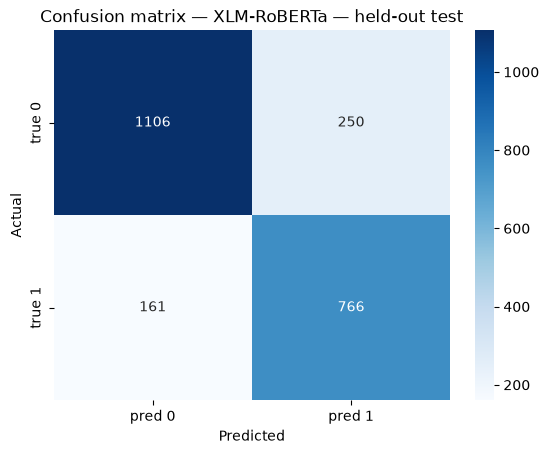

,model,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
0,XLM-RoBERTa — held-out test,0.819974,0.872928,0.815634,0.843309,0.753937,0.826321,0.788471,0.81589


In [11]:
results_df = pd.DataFrame(results)
if "val_pred_lstm" in globals():
    results_df = pd.concat([results_df, pd.DataFrame([metric_row("BiLSTM (validation)", y_val, val_pred_lstm)])], ignore_index=True)
if "val_pred_xlmr" in globals():
    results_df = pd.concat([results_df, pd.DataFrame([metric_row("XLM-RoBERTa (validation)", y_val, val_pred_xlmr)])], ignore_index=True)
results_df = results_df.drop_duplicates(subset=["model"], keep="last").sort_values("macro_f1", ascending=False)
display(results_df)


candidates = []
candidates.append(("TF-IDF word+char / LogisticRegression",
                   f1_score(y_val, val_pred_tfidf, average="macro"),
                   lambda: tfidf_model.predict(X_test)))
if "val_pred_lstm" in globals():
    candidates.append(("BiLSTM", f1_score(y_val, val_pred_lstm, average="macro"),
                       lambda: (bilstm.predict(Xte_seq, verbose=0).ravel() >= 0.5).astype(int)))
if "val_pred_xlmr" in globals():
    candidates.append(("XLM-RoBERTa", f1_score(y_val, val_pred_xlmr, average="macro"),
                       lambda: np.argmax(trainer.predict(test_ds).predictions, axis=1)))

best_name, best_val_f1, best_predict = max(candidates, key=lambda z: z[1])
print(f"Selected by validation Macro-F1: {best_name} ({best_val_f1:.4f})")
test_pred = best_predict()
test_metrics = evaluate(f"{best_name} — held-out test", y_test, test_pred)
display(pd.DataFrame([test_metrics]))

## 9. Test-set comparison of all trained models

In [12]:
# Final test metrics for each trained model
test_rows = []
test_pred_map = {}
test_pred_map["TF-IDF word+char / LogisticRegression"] = tfidf_model.predict(X_test)
if "bilstm" in globals():
    test_pred_map["BiLSTM"] = (bilstm.predict(Xte_seq, verbose=0).ravel() >= 0.5).astype(int)
if "trainer" in globals():
    test_pred_map["XLM-RoBERTa"] = np.argmax(trainer.predict(test_ds).predictions, axis=1)
for name, pred in test_pred_map.items():
    test_rows.append(metric_row(name, y_test, pred))
test_results = pd.DataFrame(test_rows).sort_values("macro_f1", ascending=False)
display(test_results)

,model,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
2,XLM-RoBERTa,0.819974,0.872928,0.815634,0.843309,0.753937,0.826321,0.788471,0.815890
0,TF-IDF word+char / LogisticRegression,0.819536,0.856495,0.836283,0.846269,0.768509,0.795038,0.781548,0.813908
1,BiLSTM,0.810775,0.876221,0.793510,0.832817,0.734597,0.836030,0.782038,0.807428


## 10. Error analysis: at least 10 misclassified test examples

In [13]:
# Use the validation-selected model's held-out test predictions.
error_df = df.iloc[idx_test].copy().reset_index(drop=True)
error_df["y_true"] = y_test
error_df["y_pred"] = test_pred
error_df = error_df[error_df["y_true"] != error_df["y_pred"]].copy()
error_df["error_type"] = np.where(
    (error_df["y_true"] == 1) & (error_df["y_pred"] == 0), "false negative (missed sarcasm)",
    "false positive (non-sarcasm predicted sarcastic)"
)
print("Misclassified test rows:", len(error_df))
display(error_df[[TEXT_COL, "y_true", "y_pred", "error_type"]].head(30))

# Create a review worksheet of 10+ examples. These categories are suggestions, not automatic truth:
# annotate manually after reading the text; phenomena can overlap.
error_review = error_df[[TEXT_COL, "y_true", "y_pred", "error_type"]].head(30).copy()
error_review["possible_linguistic_phenomenon"] = ""
error_review["human_notes"] = ""
display(error_review.head(10))
error_review.to_csv("urdu_sarcasm_error_review.csv", index=False)
print("Saved urdu_sarcasm_error_review.csv for manual annotation.")

Misclassified test rows: 411


,urdu_text,y_true,y_pred,error_type
1,ہندو گائے کو ماتا مگر بیل کو باپ نہیں مانتے فی...,0,1,false positive (non-sarcasm predicted sarcastic)
4,او باندری تجھے بس نقل نقل اور نقل کرنی ہی آتی ...,0,1,false positive (non-sarcasm predicted sarcastic)
12,جس دن جنرل صاحب کو ہدایت آے گی اس دن بہت دیر ھ...,1,0,false negative (missed sarcasm)
14,اس قرارداد میں یوکرین پر روسی حملے کا ذکر نہیں...,0,1,false positive (non-sarcasm predicted sarcastic)
19,بھئی یہ صبح سے انڈین میڈیا کی اسٹوریاں سن رہا ...,0,1,false positive (non-sarcasm predicted sarcastic)
22,کیسے ایک بدتمیز انسان نے قائد کےمزار پہ چول ما...,0,1,false positive (non-sarcasm predicted sarcastic)
24,کپڑوں کا بل ہو گا نسل در نسل چلتا آ رہا ہے 😂😂,0,1,false positive (non-sarcasm predicted sarcastic)
44,کراچی کے واقعہ پر جب تک خان صاحب بقلم خود کوئی...,0,1,false positive (non-sarcasm predicted sarcastic)
45,@NaveedAliNawabi @HamidMirPAK گالیاں دینا والو...,0,1,false positive (non-sarcasm predicted sarcastic)
51,😂😂🤣🙈🙈 اب آپ سے مذاق نہیں کرنا تو کیا پھپھو سے ...,0,1,false positive (non-sarcasm predicted sarcastic)


,urdu_text,y_true,y_pred,error_type,possible_linguistic_phenomenon,human_notes
1,ہندو گائے کو ماتا مگر بیل کو باپ نہیں مانتے فی...,0,1,false positive (non-sarcasm predicted sarcastic),,
4,او باندری تجھے بس نقل نقل اور نقل کرنی ہی آتی ...,0,1,false positive (non-sarcasm predicted sarcastic),,
12,جس دن جنرل صاحب کو ہدایت آے گی اس دن بہت دیر ھ...,1,0,false negative (missed sarcasm),,
14,اس قرارداد میں یوکرین پر روسی حملے کا ذکر نہیں...,0,1,false positive (non-sarcasm predicted sarcastic),,
19,بھئی یہ صبح سے انڈین میڈیا کی اسٹوریاں سن رہا ...,0,1,false positive (non-sarcasm predicted sarcastic),,
22,کیسے ایک بدتمیز انسان نے قائد کےمزار پہ چول ما...,0,1,false positive (non-sarcasm predicted sarcastic),,
24,کپڑوں کا بل ہو گا نسل در نسل چلتا آ رہا ہے 😂😂,0,1,false positive (non-sarcasm predicted sarcastic),,
44,کراچی کے واقعہ پر جب تک خان صاحب بقلم خود کوئی...,0,1,false positive (non-sarcasm predicted sarcastic),,
45,@NaveedAliNawabi @HamidMirPAK گالیاں دینا والو...,0,1,false positive (non-sarcasm predicted sarcastic),,
51,😂😂🤣🙈🙈 اب آپ سے مذاق نہیں کرنا تو کیا پھپھو سے ...,0,1,false positive (non-sarcasm predicted sarcastic),,


Saved urdu_sarcasm_error_review.csv for manual annotation.


## 11. Save model artifacts and reproducibility information

In [14]:
import joblib, platform
joblib.dump(tfidf_model, "tfidf_urdu_sarcasm.joblib")
tokenizer_json = tokenizer.to_json() if "tokenizer" in globals() else None
if tokenizer_json:
    with open("bilstm_tokenizer.json", "w", encoding="utf-8") as f:
        f.write(tokenizer_json)
if "bilstm" in globals():
    bilstm.save("urdu_sarcasm_bilstm.keras")
if "trainer" in globals():
    trainer.save_model("urdu_sarcasm_xlmr")
    hf_tokenizer.save_pretrained("urdu_sarcasm_xlmr")

metadata = {
    "seed": SEED,
    "text_column": TEXT_COL,
    "label_column": LABEL_COL,
    "class_mapping": {"0": "non-sarcastic", "1": "sarcastic"},
    "split": {"train": 0.70, "validation": 0.15, "test": 0.15},
    "primary_metric": "macro_f1",
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
}
with open("run_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print(json.dumps(metadata, indent=2))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{
  "seed": 42,
  "text_column": "urdu_text",
  "label_column": "is_sarcastic",
  "class_mapping": {
    "0": "non-sarcastic",
    "1": "sarcastic"
  },
  "split": {
    "train": 0.7,
    "validation": 0.15,
    "test": 0.15
  },
  "primary_metric": "macro_f1",
  "python": "3.13.15",
  "pandas": "3.0.6",
  "numpy": "2.1.3"
}
